
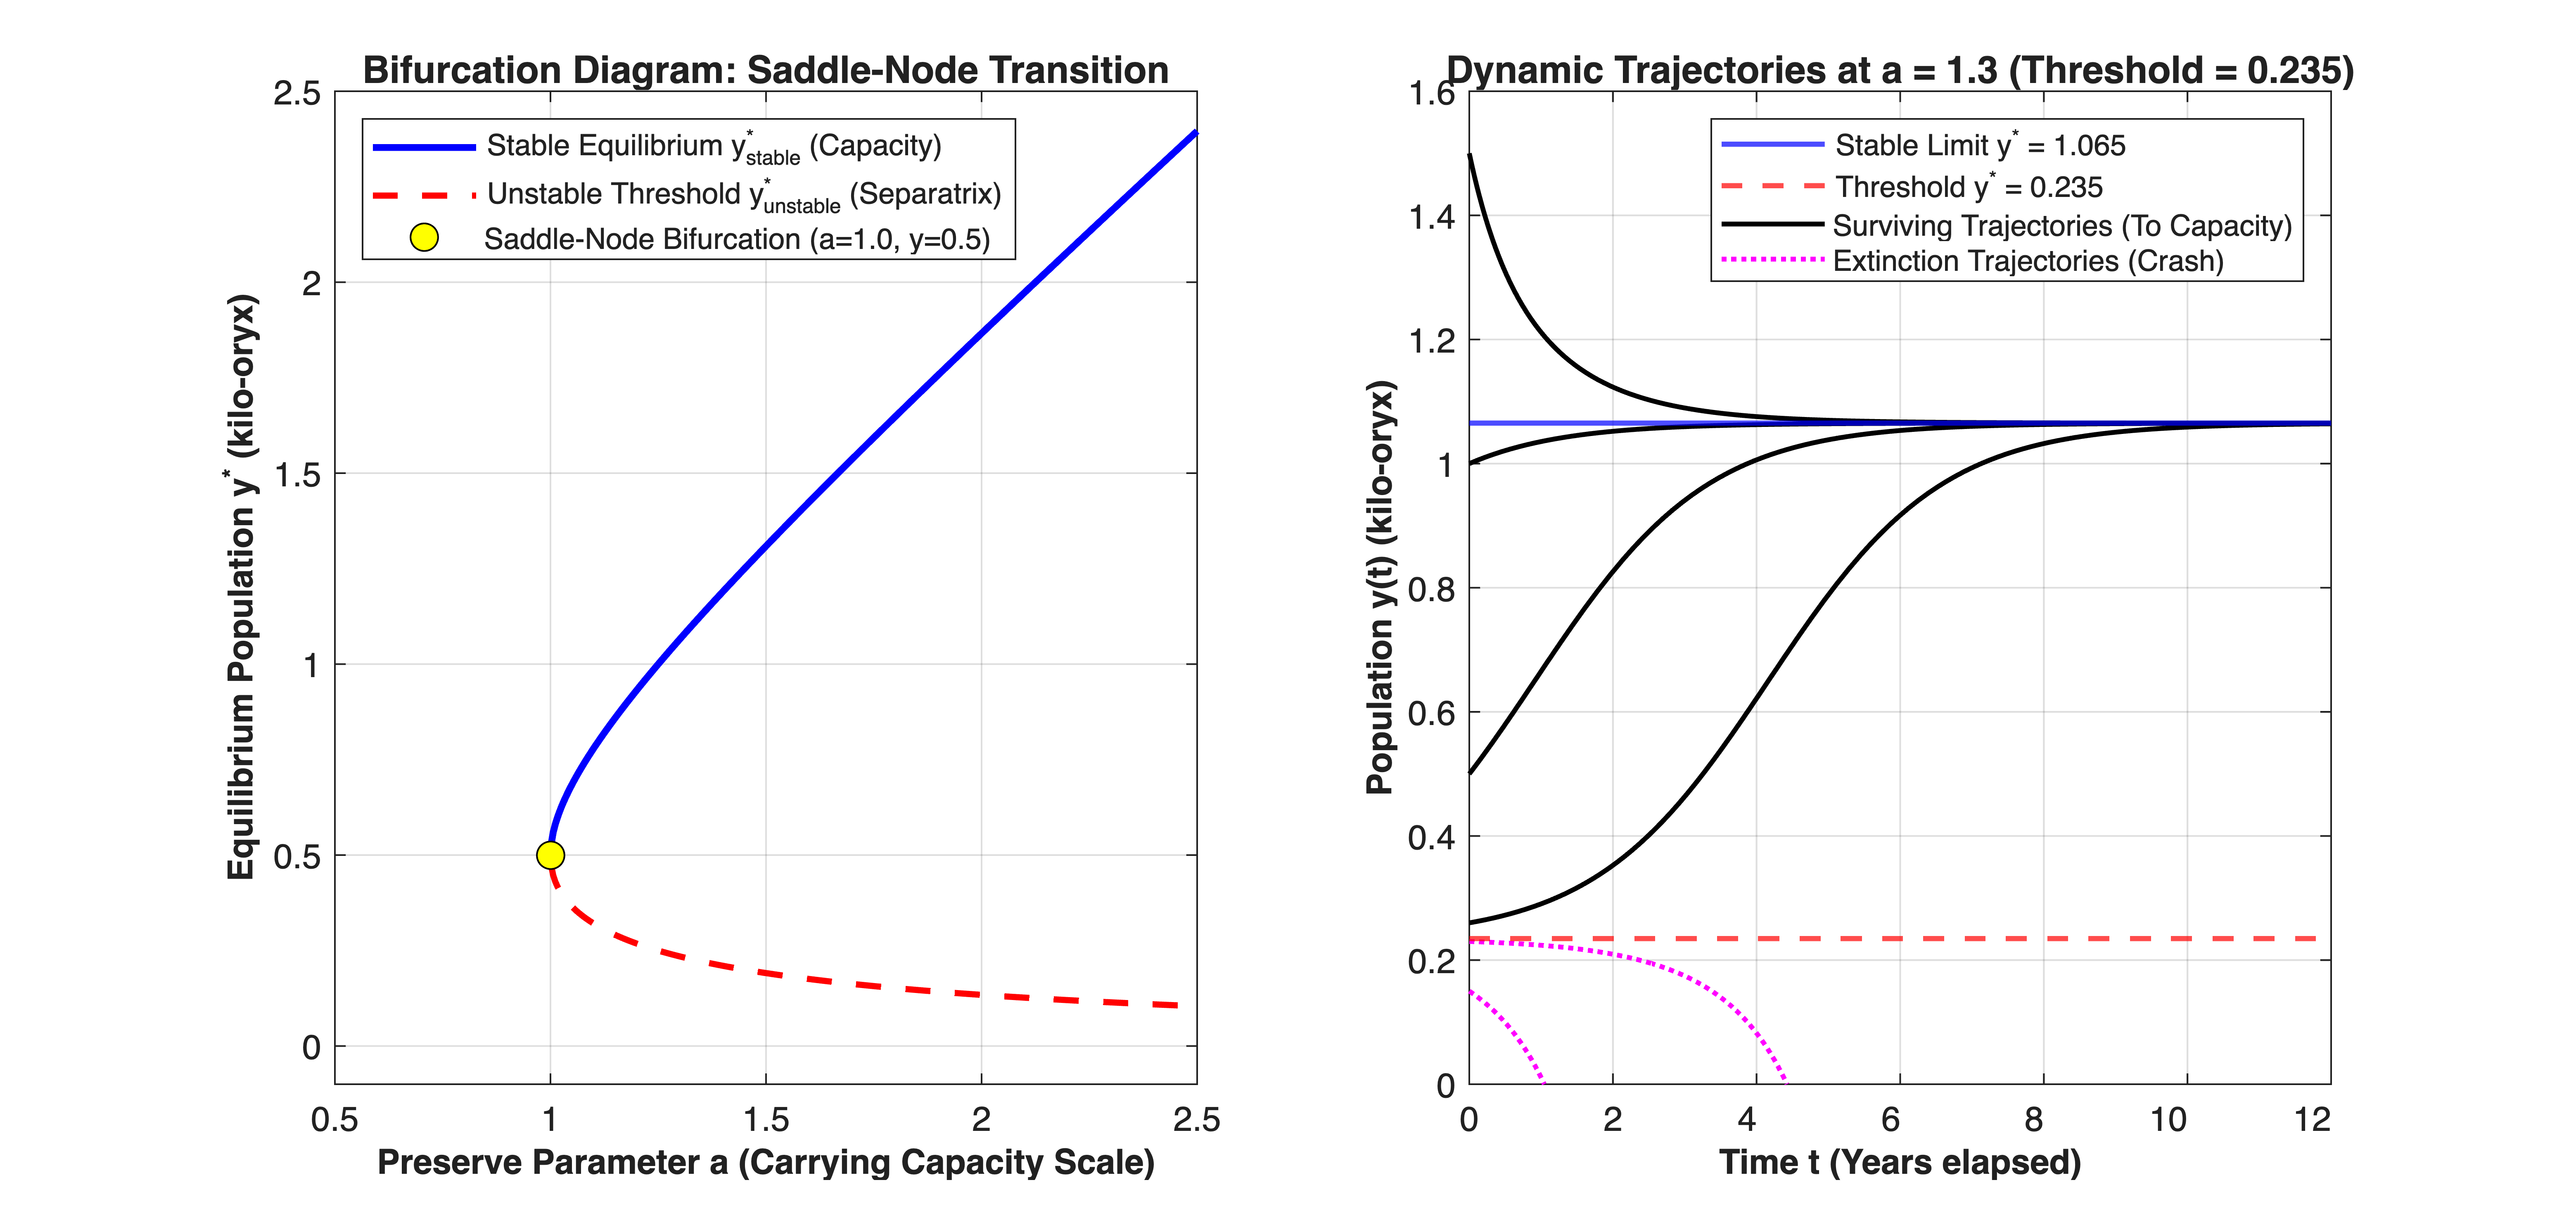

In [1]:
%% MIT 18.03 Lecture 8: Autonomous Systems, Phase Line & Saddle-Node Bifurcation (Fixed)
% Description: Simulates the Oryx harvesting model: dy/dt = (a - y)*y - h.
%              Analyzes equilibrium stability via linearization, generates the
%              bifurcation diagram, and visualizes phase line attraction basins.
%
% % Required Toolboxes:
% %   - Base MATLAB (Zero external dependency).
%
% % MBD Concept Mapping: Demonstrates nonlinear operating point trimming, local
% %                      linearization (Jacobian pole = g'(y*)), saddle-node bifurcation,
% %                      and region of attraction (ROA) boundaries.


clear; clc; close all;


%% =========================================================================
%% Part 1: Bifurcation Diagram Construction (Section [2] in Lecture)
%% =========================================================================
h_const = 0.25;
a_crit = 2 * sqrt(h_const); % Critical threshold: a = 1.0


a_sweep = linspace(0.5, 2.5, 400);
a_bifurcated = a_sweep(a_sweep >= a_crit);


% Analytical equilibria: y* = a/2 +/- 0.5 * sqrt(a^2 - 1)
y_stable_branch   = a_bifurcated/2 + 0.5 * sqrt(a_bifurcated.^2 - 4*h_const);
y_unstable_branch = a_bifurcated/2 - 0.5 * sqrt(a_bifurcated.^2 - 4*h_const);


figure('Color', [1 1 1], 'Position', [100, 100, 1100, 520]);


% Subplot 1: Bifurcation Diagram
subplot(1, 2, 1);
hold on; grid on; box on;


plot(a_bifurcated, y_stable_branch, 'b-', 'LineWidth', 2.0, ...
     'DisplayName', 'Stable Equilibrium y^*_{stable} (Capacity)');
plot(a_bifurcated, y_unstable_branch, 'r--', 'LineWidth', 1.8, ...
     'DisplayName', 'Unstable Threshold y^*_{unstable} (Separatrix)');
plot(a_crit, a_crit/2, 'ko', 'MarkerFaceColor', 'y', 'MarkerSize', 8, ...
     'DisplayName', sprintf('Saddle-Node Bifurcation (a=%.1f, y=%.1f)', a_crit, a_crit/2));


xlabel('Preserve Parameter a (Carrying Capacity Scale)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Equilibrium Population y^* (kilo-oryx)', 'FontSize', 10, 'FontWeight', 'bold');
title('Bifurcation Diagram: Saddle-Node Transition', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8.5);
xlim([0.5, 2.5]);
ylim([-0.1, 2.5]);


%% =========================================================================
%% Part 2: Time-Domain Trajectories & Basin of Attraction (a = 1.3)
%% =========================================================================
a_op = 1.3;
y_eq_high = a_op/2 + 0.5 * sqrt(a_op^2 - 4*h_const);
y_eq_low  = a_op/2 - 0.5 * sqrt(a_op^2 - 4*h_const);


subplot(1, 2, 2);
hold on; grid on; box on;


yline(y_eq_high, 'b-', 'LineWidth', 1.5, 'DisplayName', sprintf('Stable Limit y^* = %.3f', y_eq_high));
yline(y_eq_low, 'r--', 'LineWidth', 1.5, 'DisplayName', sprintf('Threshold y^* = %.3f', y_eq_low));


ode_oryx = @(t, y) (a_op - y) * y - h_const;


% Standard ODE event function handle to avoid deal() nargout mismatch
opts = odeset('RelTol', 1e-6, 'AbsTol', 1e-8, 'Events', @event_extinction);


t_span = [0, 12];
y0_candidates = [0.15, 0.23, 0.26, 0.5, 1.0, 1.5];


for idx = 1:length(y0_candidates)
    y0_val = y0_candidates(idx);
    [t_traj, y_traj, te, ~, ~] = ode45(ode_oryx, t_span, y0_val, opts);

    if isempty(te)
        plot(t_traj, y_traj, 'k-', 'LineWidth', 1.4, 'HandleVisibility', 'off');
    else
        plot(t_traj, y_traj, 'm:', 'LineWidth', 1.4, 'HandleVisibility', 'off');
    end
end


plot(NaN, NaN, 'k-', 'LineWidth', 1.4, 'DisplayName', 'Surviving Trajectories (To Capacity)');
plot(NaN, NaN, 'm:', 'LineWidth', 1.4, 'DisplayName', 'Extinction Trajectories (Crash)');


xlabel('Time t (Years elapsed)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Population y(t) (kilo-oryx)', 'FontSize', 10, 'FontWeight', 'bold');
title(sprintf('Dynamic Trajectories at a = %.1f (Threshold = %.3f)', a_op, y_eq_low), ...
      'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 8.5);
xlim([0, 12]);
ylim([0, 1.6]);

In [2]:


fprintf('=== MIT 18.03 Lec 8 Autonomous Model Metrics ===\n');

=== MIT 18.03 Lec 8 Autonomous Model Metrics ===

In [3]:
fprintf('Critical Parameter (a_crit): %.4f\n', a_crit);

Critical Parameter (a_crit): 1.0000

In [4]:
fprintf('Operating Preserve (a)     : %.4f\n', a_op);

Operating Preserve (a)     : 1.3000

In [5]:
fprintf('Stable Capacity Point      : y* = %.4f | Local Pole: %+.4f (Stable)\n', ...
        y_eq_high, a_op - 2*y_eq_high);

Stable Capacity Point      : y* = 1.0653 | Local Pole: -0.8307 (Stable)

In [6]:
fprintf('Unstable Threshold Point   : y* = %.4f | Local Pole: %+.4f (Unstable)\n', ...
        y_eq_low, a_op - 2*y_eq_low);

Unstable Threshold Point   : y* = 0.2347 | Local Pole: +0.8307 (Unstable)

In [7]:
fprintf('================================================\n');

In [8]:


%% Local Event Function
function [value, isterminal, direction] = event_extinction(~, y)
% EVENT_EXTINCTION Halts integration cleanly when population drops to 0.
% % MBD Concept Mapping: Emulates system crash boundary guards in state integration.
    value = y;          % Trigger condition: y(t) = 0
    isterminal = 1;     % Halt integration
    direction = -1;     % Negative crossing direction only
end